# 02 · Análisis de estacionalidad (tarea A4)

**Fase CRISP-DM:** comprensión y preparación de los datos. Se analizan `total` y los cuatro tipos de
tienda usando **solo el periodo de entrenamiento** (2013-01-01 a 2015-05-08), para que validación y
prueba no influyan en las decisiones del modelo. Se trabaja sobre `log1p(y)`, la escala que usan los
modelos, salvo en los efectos de calendario, que se muestran en euros.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import *
from src.features.exog import load_history

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.float_format", "{:,.3f}".format, "display.width", 160)
history = load_history()
LEVELS = ["total", *LEVELS_TYPES]

from scipy.signal import periodogram
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")  # statsmodels reactiva sus avisos al importarse
train = history[history["ds"] <= TRAIN_END]
def serie(uid):
    return train[train["unique_id"] == uid].set_index("ds")["y"].asfreq("D")
logy = {uid: np.log1p(serie(uid)) for uid in LEVELS}
print({k: (len(v), str(v.index.min().date()), str(v.index.max().date())) for k, v in logy.items()})

{'total': (858, '2013-01-01', '2015-05-08'), 'type_a': (858, '2013-01-01', '2015-05-08'), 'type_b': (858, '2013-01-01', '2015-05-08'), 'type_c': (858, '2013-01-01', '2015-05-08'), 'type_d': (858, '2013-01-01', '2015-05-08')}


## 1. Descomposición STL semanal (period = 7, robusta)

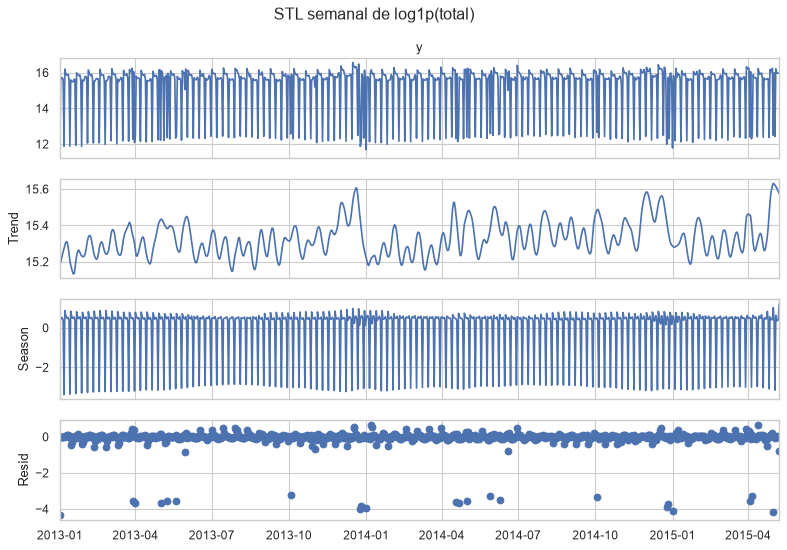

,fuerza_estacional,fuerza_tendencia
total,0.800,0.019
type_a,0.677,0.047
type_b,0.652,0.669
type_c,0.830,0.000
type_d,0.732,0.033


In [2]:
def fuerza(res):
    """Fuerza de estacionalidad y de tendencia (Hyndman): 0 = nula, 1 = dominante."""
    r = res.resid
    return {"fuerza_estacional": max(0, 1 - r.var() / (res.seasonal + r).var()),
            "fuerza_tendencia": max(0, 1 - r.var() / (res.trend + r).var())}

stl7 = {uid: STL(s, period=7, robust=True).fit() for uid, s in logy.items()}
fig = stl7["total"].plot(); fig.set_size_inches(11, 7); fig.suptitle("STL semanal de log1p(total)", y=1.01); plt.show()
display(pd.DataFrame({uid: fuerza(r) for uid, r in stl7.items()}).T)

> **Conclusión:** el patrón semanal domina la serie: su fuerza va de 0,65 (tipo b) a 0,83 (tipo c) y es 0,80 en el total. La tendencia es casi nula (≤ 0,05) en total y en los tipos a, c y d, pero importante en el tipo b (0,67). Por eso el componente estacional de periodo 7 es obligatorio y el tipo b merece un trato distinto en la diferenciación regular.

## 2. Descomposición STL anual sobre la serie semanal

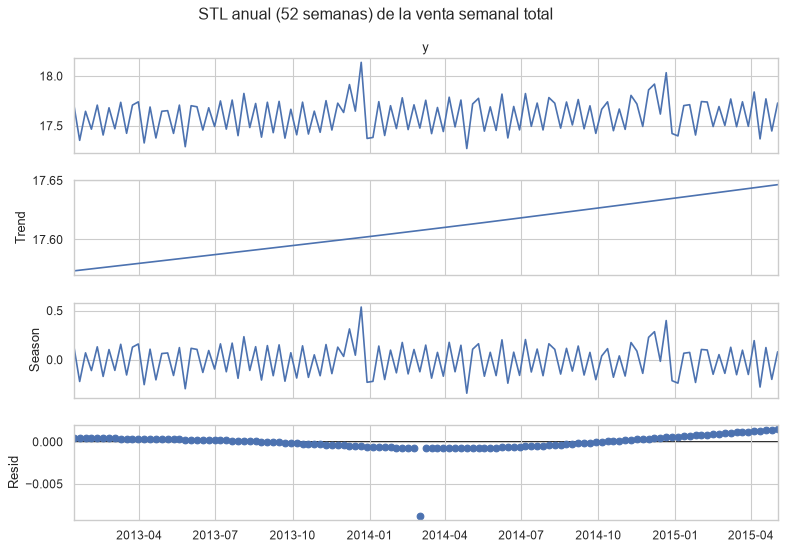

Semanas de entrenamiento: 121 | ciclos anuales: 2.33


,fuerza_estacional,fuerza_tendencia
total,1.000,0.998
type_a,1.000,0.991
type_b,0.991,0.976
type_c,1.000,0.970
type_d,0.768,0.127


In [3]:
semanal = {uid: np.log1p(serie(uid).resample("W-SUN").sum().iloc[1:-1]) for uid in LEVELS}
stl52 = {uid: STL(s, period=52, robust=True).fit() for uid, s in semanal.items()}
fig = stl52["total"].plot(); fig.set_size_inches(11, 7); fig.suptitle("STL anual (52 semanas) de la venta semanal total", y=1.01); plt.show()
print("Semanas de entrenamiento:", len(semanal["total"]), "| ciclos anuales:", round(len(semanal["total"]) / 52, 2))
display(pd.DataFrame({uid: fuerza(r) for uid, r in stl52.items()}).T)

> **Conclusión:** la descomposición muestra un patrón anual, con el pico de diciembre, pero las fuerzas cercanas a 1 **no deben leerse como evidencia fuerte**: con solo 2,33 ciclos anuales, STL tiene muy pocos datos por semana del año y el componente estacional absorbe casi toda la variación. Se usa como apoyo visual; la evidencia del ciclo anual está en la sección 5 y en los promedios por mes de la sección 6.

## 3. ACF y PACF (lags 0 a 60)

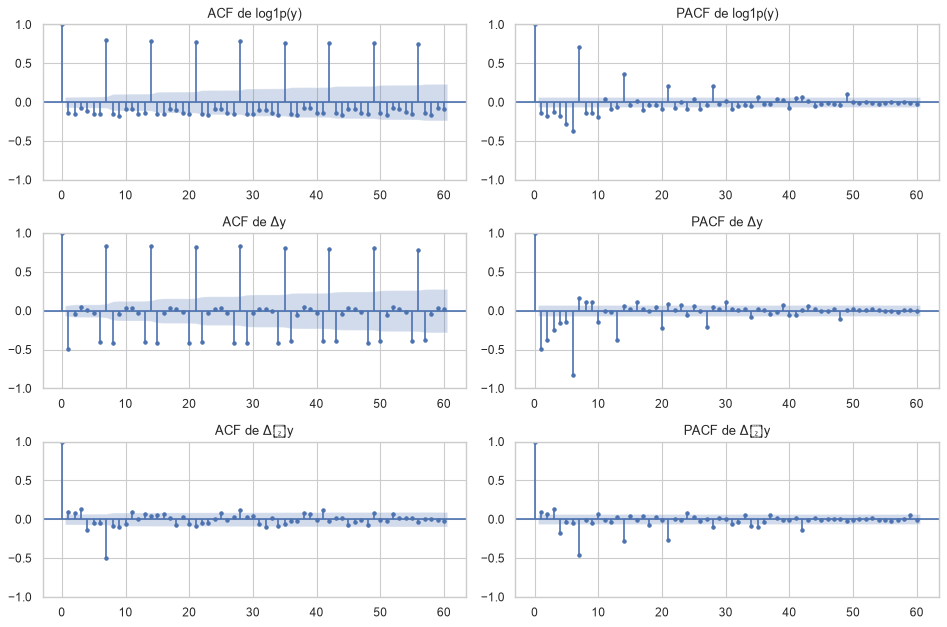

,log1p(y),Δy,Δ₇y
ACF lag 1,-0.135,-0.488,0.098
ACF lag 2,-0.156,-0.045,0.074
ACF lag 7,0.795,0.838,-0.495
ACF lag 14,0.793,0.828,0.039
ACF lag 21,0.775,0.824,-0.084
ACF lag 28,0.789,0.830,0.113


PACF de Δ₇y en lags 1, 2, 7, 14: [ 0.098  0.065 -0.466 -0.282]


In [4]:
y = logy["total"]
versiones = {"log1p(y)": y, "Δy": y.diff().dropna(), "Δ₇y": y.diff(7).dropna()}
fig, axes = plt.subplots(3, 2, figsize=(12, 8))
for (nombre, s), (a, b) in zip(versiones.items(), axes):
    plot_acf(s, lags=60, ax=a, title=f"ACF de {nombre}", markersize=3)
    plot_pacf(s, lags=60, ax=b, title=f"PACF de {nombre}", markersize=3, method="ywm")
plt.tight_layout(); plt.show()
from statsmodels.tsa.stattools import acf, pacf
tabla = pd.DataFrame({n: acf(s, nlags=28)[[1, 2, 7, 14, 21, 28]] for n, s in versiones.items()}, index=[f"ACF lag {k}" for k in [1, 2, 7, 14, 21, 28]])
display(tabla)
d7 = versiones["Δ₇y"]
print("PACF de Δ₇y en lags 1, 2, 7, 14:", pacf(d7, nlags=14, method="ywm")[[1, 2, 7, 14]].round(3))

> **Conclusión:** en `log1p(y)` la ACF es alta y casi no decae en los múltiplos de 7 (0,80 en el lag 7 y 0,79 en el lag 28). La diferencia simple no lo corrige (0,84 en el lag 7), mientras que la diferencia estacional sí: en Δ₇y queda un único pico negativo en el lag 7 (−0,50) y los lags 14 y 21 son pequeños (0,04 y −0,08). La PACF de Δ₇y decae en los múltiplos de 7 (−0,47 y −0,28), la firma de un término **MA estacional (Q = 1)**. Los lags 1 y 2 son débiles (0,10 y 0,07), así que bastan órdenes p y q bajos.

## 4. Pruebas de estacionariedad

**ADF:** H0 = hay raíz unitaria (no estacionaria); p < 0,05 apoya estacionariedad.
**KPSS:** H0 = estacionaria; p < 0,05 la rechaza. `statsmodels` acota el p-valor de KPSS a [0,01; 0,10].

In [5]:
filas = []
for uid, s in logy.items():
    for nombre, v in {"y": s, "Δy": s.diff().dropna(), "Δ₇y": s.diff(7).dropna()}.items():
        filas.append({"nivel": uid, "serie": nombre, "ADF p": adfuller(v, autolag="AIC")[1],
                      "KPSS p": kpss(v, regression="c", nlags="auto")[1]})
pruebas = pd.DataFrame(filas)
pruebas["conclusión"] = np.select(
    [(pruebas["ADF p"] < .05) & (pruebas["KPSS p"] >= .05), (pruebas["ADF p"] >= .05) & (pruebas["KPSS p"] < .05)],
    ["estacionaria", "no estacionaria"], "resultado mixto")
display(pruebas.pivot(index="nivel", columns="serie", values=["ADF p", "KPSS p", "conclusión"]))

ADF p             KPSS p                   conclusión                            
serie      y    Δy   Δ₇y      y    Δy   Δ₇y                y            Δy           Δ₇y
nivel                                                                                   
total  0.000 0.000 0.000  0.100 0.100 0.100     estacionaria  estacionaria  estacionaria
type_a 0.003 0.000 0.000  0.100 0.100 0.100     estacionaria  estacionaria  estacionaria
type_b 0.004 0.000 0.000  0.010 0.100 0.100  resultado mixto  estacionaria  estacionaria
type_c 0.000 0.000 0.000  0.100 0.100 0.100     estacionaria  estacionaria  estacionaria
type_d 0.008 0.000 0.000  0.100 0.100 0.100     estacionaria  estacionaria  estacionaria

> **Conclusión:** según ADF y KPSS, `log1p(y)` ya es estacionaria en total y en los tipos a, c y d, así que no hace falta diferencia regular (**d = 0**). El tipo b da un resultado mixto (KPSS rechaza, p ≤ 0,01), coherente con su tendencia, y se estabiliza con Δy (**d = 1**). Estas pruebas no detectan bien la estacionalidad determinista: la necesidad de D = 1 sale de la ACF de la sección 3, no de ellas. Para las tiendas, `choose_d` aplica esta misma regla automáticamente.

## 5. Periodograma

,pico 1 (días),pico 2 (días),pico 3 (días),pico 4 (días)
nivel,,,,
total,3.502,2.332,6.976,7.033
type_a,3.502,2.332,6.976,7.033
type_b,3.502,2.332,15.053,6.976
type_c,3.502,2.332,6.976,7.033
type_d,3.502,2.332,6.976,7.033


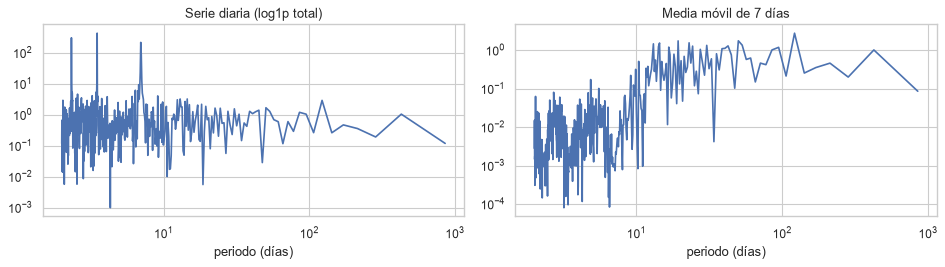

Periodos dominantes sin el patrón semanal (días): [121.7  50.1  19.4  23.   14.4]
Resolución cerca de un año: periodos vecinos [426. 284.]
Correlación semana vs. misma semana del año anterior: r = 0.416 con 69 pares (banda aprox. ±0.236)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
filas = []
for uid, s in logy.items():
    f, p = periodogram(s.to_numpy() - s.mean(), fs=1.0, detrend="linear")
    f, p = f[1:], p[1:]
    top = np.argsort(p)[::-1][:4]
    filas.append({"nivel": uid, **{f"pico {i+1} (días)": 1 / f[j] for i, j in enumerate(top)}})
    if uid == "total":
        axes[0].semilogy(1 / f, p); axes[0].set_xscale("log"); axes[0].set_title("Serie diaria (log1p total)"); axes[0].set_xlabel("periodo (días)")
display(pd.DataFrame(filas).set_index("nivel"))
# Sin el patrón semanal: promedio móvil centrado de 7 días, para aislar periodos largos
lento = logy["total"].rolling(7, center=True).mean().dropna()
f, p = periodogram(lento.to_numpy(), fs=1.0, detrend="linear"); f, p = f[1:], p[1:]
axes[1].semilogy(1 / f, p); axes[1].set_xscale("log"); axes[1].set_title("Media móvil de 7 días"); axes[1].set_xlabel("periodo (días)")
plt.tight_layout(); plt.show()
top = np.argsort(p)[::-1][:5]
print("Periodos dominantes sin el patrón semanal (días):", np.round(1 / f[top], 1))
print("Resolución cerca de un año: periodos vecinos", np.round([len(lento) / 2, len(lento) / 3], 0))
# Prueba directa del ciclo anual: ¿se parece cada semana a la misma semana del año anterior?
sem = semanal["total"]
sin_tend = pd.Series(sem.to_numpy() - np.polyval(np.polyfit(np.arange(len(sem)), sem, 1), np.arange(len(sem))), index=sem.index)
pares = pd.concat([sin_tend, sin_tend.shift(52)], axis=1).dropna()
r = pares.corr().iloc[0, 1]
print(f"Correlación semana vs. misma semana del año anterior: r = {r:.3f} con {len(pares)} pares (banda aprox. ±{1.96 / np.sqrt(len(pares)):.3f})")

> **Conclusión:** el periodo de **7 días** queda confirmado, junto con sus armónicos de 3,5 y 2,33 días, que aparecen porque el patrón semanal no es senoidal (el domingo cae de golpe). El periodograma **no puede confirmar por sí solo los ~365 días**: con 2,35 años de datos, las frecuencias vecinas corresponden a 426 y 284 días, sin resolución para aislar 365. El ciclo anual se comprueba de otra forma: cada semana se correlaciona con la misma semana del año anterior (r = 0,42 con 69 pares, por encima de la banda de ±0,24).

## 6. Efectos de calendario

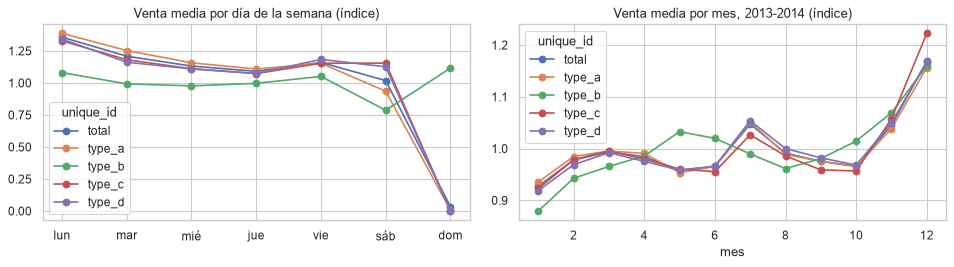

unique_id,total,type_a,type_b,type_c,type_d
lun,1.360,1.390,1.080,1.330,1.340
mar,1.210,1.250,0.990,1.180,1.160
mié,1.130,1.160,0.980,1.110,1.110
jue,1.090,1.110,1.000,1.070,1.070
vie,1.160,1.150,1.050,1.150,1.180
sáb,1.020,0.940,0.790,1.150,1.130
dom,0.030,0.010,1.120,0.000,0.000


unique_id,total,type_a,type_b,type_c,type_d
mes,,,,,
1,0.930,0.940,0.880,0.920,0.920
2,0.980,0.980,0.940,0.980,0.970
3,0.990,1.000,0.970,1.000,0.990
4,0.980,0.990,0.990,0.980,0.980
5,0.960,0.950,1.030,0.960,0.960
6,0.970,0.970,1.020,0.960,0.970
7,1.050,1.050,0.990,1.030,1.050
8,0.990,0.990,0.960,0.990,1.000
9,0.980,0.980,0.980,0.960,0.980


In [7]:
t = train[train["unique_id"].isin(LEVELS)].copy()
t["dow"] = t["ds"].dt.dayofweek; t["mes"] = t["ds"].dt.month
dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
dow = t.pivot_table(index="dow", columns="unique_id", values="y")[LEVELS]; dow.index = dias
mes = t[t["ds"] < "2015-01-01"].pivot_table(index="mes", columns="unique_id", values="y")[LEVELS]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
(dow / dow.mean()).plot(ax=axes[0], marker="o", title="Venta media por día de la semana (índice)")
(mes / mes.mean()).plot(ax=axes[1], marker="o", title="Venta media por mes, 2013-2014 (índice)")
plt.tight_layout(); plt.show()
display((dow / dow.mean()).round(2)); display((mes / mes.mean()).round(2))

> **Conclusión:** el lunes es el mejor día (índice 1,36 en el total) y la venta baja hasta el jueves. El domingo casi desaparece (0,03) porque cierran casi todas las tiendas, salvo en el **tipo b**, que abre y vende por encima de su media (1,12): esto justifica la exógena `open_share`. Por mes destacan diciembre (+17 %), noviembre y julio (+5 %), y enero es el más bajo (−7 %), un patrón anual suave que se repite en todos los tipos.

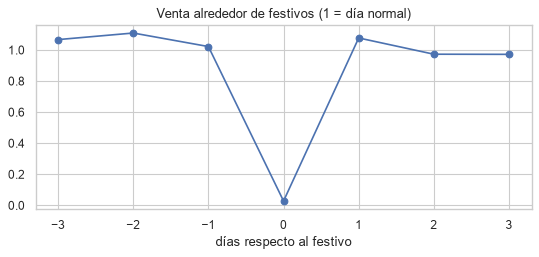

Festivos laborables en entrenamiento: 25


,-3,-2,-1,0,1,2,3
venta relativa (mediana),1.067,1.109,1.022,0.028,1.077,0.973,0.972


In [8]:
tot = train[train["unique_id"] == "total"].set_index("ds").sort_index()
# Referencia: la mediana del mismo día de la semana, para no confundir festivo con domingo
ref = tot.groupby(tot.index.dayofweek)["y"].transform("median")
rel = tot["y"] / ref
fest = tot.index[(tot["state_holiday"] != "0") & (tot.index.dayofweek < 6)]
perfil = pd.DataFrame({k: rel.reindex(fest + pd.Timedelta(days=k)).to_numpy() for k in range(-3, 4)}, index=fest)
res = perfil.median().rename("venta relativa (mediana)")
ax = res.plot(marker="o", figsize=(8, 3), title="Venta alrededor de festivos (1 = día normal)"); ax.set_xlabel("días respecto al festivo"); plt.show()
print("Festivos laborables en entrenamiento:", len(fest)); display(res.to_frame().T)

> **Conclusión:** un festivo laborable vende apenas un 2,8 % de un día normal, porque cierran casi todas las tiendas. Hay un adelanto de compras dos días antes (+11 %) y un rebote al día siguiente (+8 %). La caída del propio día queda recogida por `sh_a`, `sh_b`, `sh_c` y `open_share`; el adelanto y el rebote no tienen variable propia y quedan como error conocido.

,días con promo,días sin promo,venta con promo,venta sin promo,aumento %
nivel,,,,,
total,321,268,"9,087,441.255","6,538,923.720",38.975
type_a,321,268,"4,958,262.019","3,595,841.668",37.889
type_b,321,269,"185,341.396","153,415.636",20.810
type_c,321,269,"1,177,259.103","842,097.654",39.801
type_d,321,268,"2,766,578.738","1,947,234.769",42.077


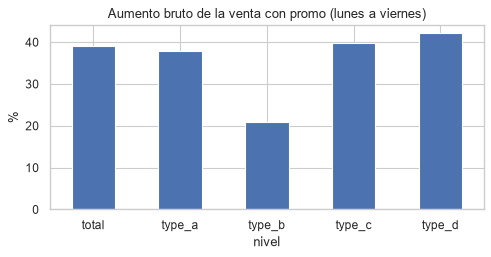

In [9]:
filas = []
for uid in LEVELS:
    g = train[(train["unique_id"] == uid) & (train["ds"].dt.dayofweek < 5) & (train["state_holiday"] == "0") & (train["y"] > 0)]
    con = g[g["promo_share"] >= .5]; sin = g[g["promo_share"] < .5]
    filas.append({"nivel": uid, "días con promo": len(con), "días sin promo": len(sin), "venta con promo": con["y"].mean(),
                  "venta sin promo": sin["y"].mean(), "aumento %": (con["y"].mean() / sin["y"].mean() - 1) * 100})
promo = pd.DataFrame(filas).set_index("nivel"); display(promo)
ax = promo["aumento %"].plot.bar(figsize=(7, 3), title="Aumento bruto de la venta con promo (lunes a viernes)", rot=0); ax.set_ylabel("%"); plt.show()

> **Conclusión:** de lunes a viernes, sin festivos, la venta es un 39 % mayor con promo en el total; 42 % en el tipo d, 40 % en el c, 38 % en el a y solo 21 % en el b. Son diferencias **brutas**, sin controlar por el día de la semana ni por el mes. El efecto ajustado se estima con SARIMAX en `04_sarimax_exogenas.ipynb`.

## 7. Conclusión: órdenes de diferenciación y tratamiento de la estacionalidad

| Decisión | Valor | Evidencia |
| --- | --- | --- |
| Periodo estacional **s** | 7 | Fuerza estacional de 0,65 a 0,83 y picos de ACF en múltiplos de 7 |
| Diferencia estacional **D** | 1 | ACF de 0,80 sin decaer en lags estacionales; Δ₇y la limpia |
| Diferencia regular **d** | 0 (total y tipos a, c, d); 1 (tipo b) | ADF y KPSS, con la regla `choose_d` |
| **Q** esperado | 1 | Pico único de ACF en el lag 7 de Δ₇y y PACF que decae |
| **p, q** | bajos, entre 0 y 2 | Lags 1 y 2 débiles en Δ₇y |

**Por qué la estacionalidad anual va con términos de Fourier y no con SARIMA s = 365:**

1. **Datos insuficientes.** Una diferencia con s = 365 gastaría un año completo de los 2,35 disponibles y dejaría muy pocos ciclos para estimar los términos estacionales.
2. **Costo computacional.** El espacio de estados de SARIMAX crece con s: con s = 365 tendría cientos de estados, lo que hace el ajuste lento e inestable, y el archivo del simulador sería mucho más pesado.
3. **El ciclo es suave.** Los promedios mensuales varían poco, salvo diciembre y enero, y tres pares de seno y coseno (6 parámetros) lo describen sin gastar observaciones.
4. **El año no es múltiplo de la semana.** Fourier admite un periodo de 365,25 días y se conoce de antemano para cualquier fecha futura, así que no introduce fuga.